# Projet NLP — BERT vs TF-IDF sur SST-2

## 0 — Introduction et configuration

**Phase 1 uniquement : exploration et baseline, sur CPU.**

Nous étudions la classification binaire du sentiment de critiques de films en anglais.
L'objectif général est de comparer une représentation lexicale TF-IDF suivie d'une
régression logistique à BERT, un encodeur Transformer préentraîné qui produit des
représentations contextuelles. La baseline apprend ici ses poids uniquement à partir
du train ; l'approche contextuelle sera développée après validation de cette phase.

Ce notebook couvre les étapes **Explore** et **Baseline** du module 7 du cours
(diapositives « Hands-on » et « Exercise roadmap »). Aucune implémentation de BERT,
de son tokenizer ou du fine-tuning n'est incluse.

**Protocole fixé avant évaluation :** train officiel pour apprendre le vocabulaire,
les IDF et le classifieur ; validation officielle pour mesurer les performances.
Pas de recherche d'hyperparamètres sur la validation. Le split test, dont les labels
ne sont pas publics, ne sert à aucune analyse ni mesure. Les futurs modèles devront
être évalués sur les mêmes 872 exemples de validation. Cette validation n'est pas
un test final indépendant, en particulier si elle guide ensuite le choix des modèles.

Exécuter toutes les cellules dans l'ordre. Sur Colab, choisir **CPU**, puis
**Exécution → Tout exécuter**. Une connexion Internet est nécessaire pour installer
les bibliothèques et télécharger SST-2 lors du premier lancement.


### Dépendances

La cellule suivante reprend les bornes de `requirements.txt` et fonctionne aussi
quand le notebook est importé seul dans Colab. Python **3.11 à 3.13** est recommandé.
Les versions réellement utilisées seront affichées et enregistrées dans le JSON.
PyTorch et Transformers ne sont pas nécessaires à cette phase.

Si Colab demande un redémarrage après une installation, redémarrer la session et
relancer toutes les cellules. Les bornes évitent les nouvelles versions majeures de
pandas/datasets et les changements d'API de scikit-learn à partir de 1.8.


In [1]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\PAVILION\Downloads\nlp-bert-vs-tfidf-sst2\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import platform
import random
import sys
from time import perf_counter
import warnings
from zipfile import ZipFile

# Depuis notebooks/, les exports vont dans ../results/ ; dans Colab, dans ./results/.
working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "notebooks" else working_dir
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
LABEL_NAMES = {0: "négatif", 1: "positif"}
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ("numpy", "pandas", "scikit-learn", "matplotlib", "datasets", "ipython")
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 11})
pd.set_option("display.max_colwidth", 160)

print(f"Environnement : {'Google Colab' if IN_COLAB else 'Jupyter / local'}")
print(f"Python : {sys.version.split()[0]} | système : {platform.system()}")
print(f"Calcul : CPU | seed : {SEED} | dossier des résultats : {RESULTS_DIR}")
display(pd.Series(VERSIONS, name="version").to_frame())


C:\Users\PAVILION\Downloads\nlp-bert-vs-tfidf-sst2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environnement : Jupyter / local
Python : 3.13.14 | système : Windows
Calcul : CPU | seed : 42 | dossier des résultats : C:\Users\PAVILION\Downloads\nlp-bert-vs-tfidf-sst2\results


,version
numpy,2.5.5
pandas,2.3.3
scikit-learn,1.7.2
matplotlib,3.10.9
datasets,4.8.5
ipython,9.18.1


## 1 — Exploration SST-2

[SST-2 dans GLUE](https://huggingface.co/datasets/nyu-mll/glue) contient des textes
issus du Stanford Sentiment Treebank, avec **0 = négatif** et **1 = positif**.
Le train comprend aussi des fragments annotés ; il ne faut donc pas supposer que
ses longueurs suivent exactement la distribution des phrases de validation.

Le chargement ci-dessous récupère la configuration SST-2 officielle. Seuls les
splits `train` et `validation` sont ensuite consultés. Nous vérifions leurs tailles,
les labels et la présence de textes exploitables avant tout entraînement.


In [3]:
dataset = load_dataset("nyu-mll/glue", "sst2")
train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
frames = {"train": train_df, "validation": validation_df}

assert len(train_df) == 67_349, "Taille inattendue du split train."
assert len(validation_df) == 872, "Taille inattendue du split validation."
for split_name, frame in frames.items():
    assert {"sentence", "label", "idx"}.issubset(frame.columns), split_name
    assert frame["sentence"].notna().all(), split_name
    assert frame["sentence"].str.strip().str.len().gt(0).all(), split_name
    assert set(frame["label"].unique()) == {0, 1}, split_name
    assert frame["idx"].is_unique, split_name

dimensions = pd.DataFrame([
    {"split": name, "exemples": len(frame), "colonnes_source": frame.shape[1]}
    for name, frame in frames.items()
]).set_index("split")
display(dimensions)
print("Colonnes source :", list(train_df.columns))

# Exemples équilibrés pour illustrer les deux annotations, sans entraîner de modèle.
examples = pd.concat([
    train_df.loc[train_df["label"].eq(label)].sample(n=3, random_state=SEED)
    for label in (0, 1)
]).copy()
examples["sentiment"] = examples["label"].map(LABEL_NAMES)
display(examples[["sentence", "label", "sentiment"]].reset_index(drop=True))


,exemples,colonnes_source
split,,
train,67349,3
validation,872,3


Colonnes source : ['sentence', 'label', 'idx']


,sentence,label,sentiment
0,"a dull , dumb and derivative horror",0,négatif
1,"if george romero had directed this movie , it would n't have taken the protagonists a full hour to determine that in order to kill a zombie you must shoot i...",0,négatif
2,"the acting is amateurish , the cinematography is atrocious",0,négatif
3,"acted meditation on both the profoundly devastating events of one year ago and the slow , painful healing process that has followed in their wake",1,positif
4,"this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton 's ever-watchful gaze -- and it 's a tribute to the actress ...",1,positif
5,"directed with purpose and finesse by england 's roger mitchell , who handily makes the move from pleasing , relatively lightweight commercial fare such as n...",1,positif


,négatif,positif
split,,
train,29780,37569
validation,428,444


,négatif (%),positif (%)
split,,
train,44.22,55.78
validation,49.08,50.92


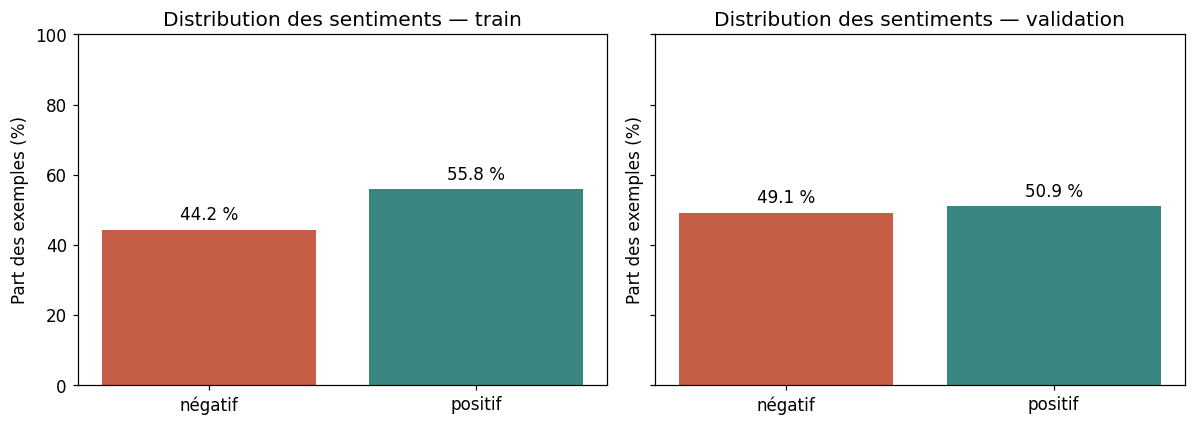

Le sentiment positif représente **55.8 %** du train et **50.9 %** de la validation. Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué.

In [4]:
class_counts = pd.DataFrame({
    name: frame["label"].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in frames.items()
}).T
class_counts.columns = [LABEL_NAMES[0], LABEL_NAMES[1]]
class_percentages = class_counts.div(class_counts.sum(axis=1), axis=0).mul(100)
display(class_counts.rename_axis("split"))
display(class_percentages.round(2).rename_axis("split").add_suffix(" (%)"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, frames):
    values = class_percentages.loc[name]
    bars = ax.bar(values.index, values.values, color=["#C65D46", "#378780"])
    ax.bar_label(bars, labels=[f"{value:.1f} %" for value in values], padding=4)
    ax.set(title=f"Distribution des sentiments — {name}", ylim=(0, 100), ylabel="Part des exemples (%)")
fig.tight_layout()
plt.show()

display(Markdown(
    f"Le sentiment positif représente **{class_percentages.loc['train', 'positif']:.1f} %** du train "
    f"et **{class_percentages.loc['validation', 'positif']:.1f} %** de la validation. "
    "Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 "
    "complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué."
))


### Longueur des textes et contrôle des recouvrements

Le nombre de **mots** est estimé par une séparation sur les espaces, ponctuation
comprise ; le nombre de **caractères** inclut les espaces. Il s'agit de mesures
descriptives, distinctes des unités que retient `TfidfVectorizer`.

Le contrôle des doublons ci-dessous recherche les textes identiques après passage
en minuscules et normalisation des espaces. Il ne détecte pas tous les fragments
qui se recouvrent ni les paraphrases. Les splits officiels sont conservés pour la
comparabilité : un éventuel recouvrement provenant du corpus sera signalé, sans
suppression silencieuse d'exemples. Le vocabulaire et les IDF restent appris sur le
train uniquement, indépendamment de ces observations descriptives.


count    mean    std  min    50%    90%     95%  \
split      mesure                                                            
train      n_words       67349.0    9.41   8.07  1.0    7.0   21.0   26.00   
           n_characters  67349.0   53.51  43.41  2.0   39.0  117.0  145.00   
validation n_words         872.0   19.55   8.76  2.0   19.0   31.9   34.45   
           n_characters    872.0  105.84  48.13  6.0  103.0  171.0  186.45   

                            99%    max  
split      mesure                       
train      n_words        35.00   52.0  
           n_characters  194.00  268.0  
validation n_words        42.00   47.0  
           n_characters  222.29  244.0

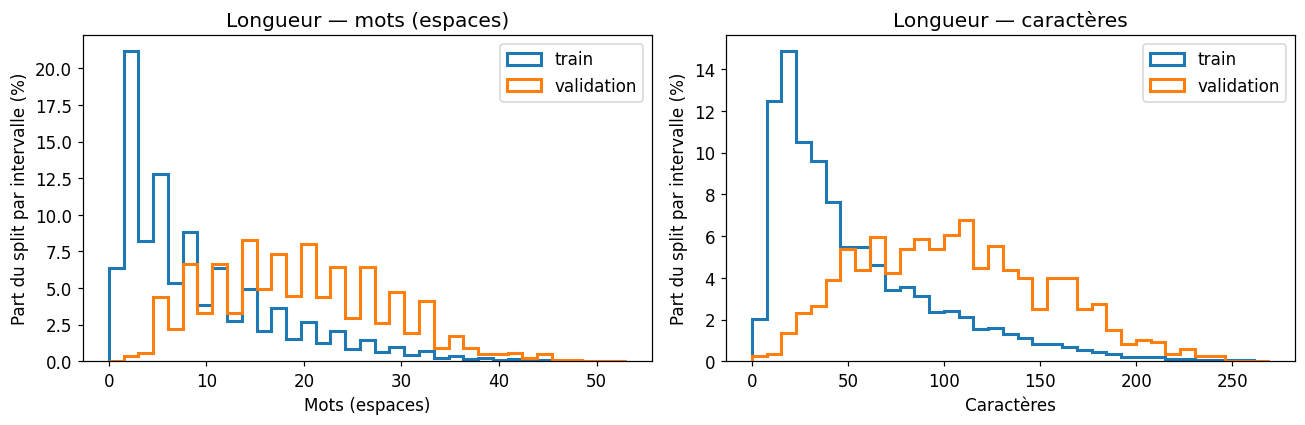

La longueur médiane est de **7 mots** dans le train et **19 mots** dans la validation. La présence de fragments dans le train peut contribuer à cet écart ; ces statistiques ne suffisent pas à en établir toutes les causes. La baseline conserve les textes entiers, sans troncature.

Doublons internes normalisés : {'train': 371, 'validation': 0}
Textes normalisés communs aux splits : 0
Lignes de validation concernées : 0
Aucun texte entier identique détecté avec cette normalisation.


In [5]:
for frame in frames.values():
    frame["n_words"] = frame["sentence"].str.split().str.len()
    frame["n_characters"] = frame["sentence"].str.len()

length_stats = pd.concat({
    name: frame[["n_words", "n_characters"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T
    for name, frame in frames.items()
}, names=["split", "mesure"])
display(length_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in zip(axes, ["n_words", "n_characters"], ["Mots (espaces)", "Caractères"]):
    maximum = max(frame[column].max() for frame in frames.values())
    bins = np.linspace(0, maximum + 1, 36)
    for name, frame in frames.items():
        # Pondération en pourcentage pour comparer des splits de tailles différentes.
        ax.hist(frame[column], bins=bins, weights=np.full(len(frame), 100 / len(frame)),
                histtype="step", linewidth=2, label=name)
    ax.set(xlabel=label, ylabel="Part du split par intervalle (%)", title=f"Longueur — {label.lower()}")
    ax.legend()
fig.tight_layout()
plt.show()

train_median = train_df["n_words"].median()
validation_median = validation_df["n_words"].median()
display(Markdown(
    f"La longueur médiane est de **{train_median:.0f} mots** dans le train et "
    f"**{validation_median:.0f} mots** dans la validation. "
    "La présence de fragments dans le train peut contribuer à cet écart ; "
    "ces statistiques ne suffisent pas à en établir toutes les causes. "
    "La baseline conserve les textes entiers, sans troncature."
))

normalized_texts = {
    name: frame["sentence"].str.lower().str.split().str.join(" ")
    for name, frame in frames.items()
}
overlap_texts = set(normalized_texts["train"]) & set(normalized_texts["validation"])
overlap_validation_rows = int(normalized_texts["validation"].isin(overlap_texts).sum())
print("Doublons internes normalisés :", {
    name: int(texts.duplicated().sum()) for name, texts in normalized_texts.items()
})
print(f"Textes normalisés communs aux splits : {len(overlap_texts)}")
print(f"Lignes de validation concernées : {overlap_validation_rows}")
if overlap_texts:
    display(Markdown(
        "**Limite du corpus :** des textes identiques sont présents dans les deux splits. "
        "L'évaluation conserve le protocole officiel ; cette dépendance doit être "
        "mentionnée lors de l'interprétation des scores."
    ))
else:
    print("Aucun texte entier identique détecté avec cette normalisation.")


## 2 — Baseline TF-IDF + régression logistique

Les hyperparamètres suivants sont fixés **sans optimisation sur la validation**.

| Élément | Paramètres et motivation |
| --- | --- |
| TF-IDF | `ngram_range=(1, 2)` : mots et paires de mots pour des indices locaux tels que « not good ». |
| Vocabulaire | `min_df=2`, `max_df=1.0`, `max_features=100000` : écarter les termes présents dans un seul document et limiter la mémoire. |
| Pondération | `sublinear_tf=True`, `use_idf=True`, `smooth_idf=True`, `norm='l2'` : fréquence logarithmique et normalisation par document. |
| Texte | Minuscules ; ni stopwords ni lemmatisation pour conserver notamment les négations. Le motif standard retient les suites d'au moins deux caractères de mot et sépare aux ponctuations. |
| Classifieur | `C=1.0`, pénalité L2, `solver='lbfgs'`, `max_iter=1000`, `tol=1e-4`, `class_weight=None`, `random_state=42`. |

`Pipeline.fit` reçoit exclusivement les 67 349 textes et labels du train.
`Pipeline.predict` transforme la validation avec le vocabulaire et les IDF déjà
appris. Aucune matrice dense n'est créée. Un défaut de convergence interrompt
l'exécution pour éviter d'exporter discrètement une baseline non convergée.

La seed fixe les tirages d'exemples et les composants qui utilisent un générateur
aléatoire. De petites variations numériques restent possibles selon les versions
des bibliothèques et les bibliothèques de calcul du système.


In [6]:
X_train = train_df["sentence"].tolist()
y_train = train_df["label"].to_numpy(dtype=np.int64)
X_validation = validation_df["sentence"].tolist()
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 1.0,
    "max_features": 100_000,
    "lowercase": True,
    "stop_words": None,
    "sublinear_tf": True,
    "use_idf": True,
    "smooth_idf": True,
    "norm": "l2",
}
LOGREG_PARAMS = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 1000,
    "tol": 1e-4,
    "class_weight": None,
    "random_state": SEED,
}
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("logreg", LogisticRegression(**LOGREG_PARAMS)),
])

training_start = perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    baseline.fit(X_train, y_train)
training_seconds = perf_counter() - training_start
y_pred = baseline.predict(X_validation)

assert len(y_pred) == 872
assert set(np.unique(y_pred)).issubset({0, 1})
print(f"Entraînement CPU : {training_seconds:.2f} s")
print(f"Vocabulaire appris sur train : {len(baseline.named_steps['tfidf'].vocabulary_):,} caractéristiques")
print("Itérations du classifieur :", baseline.named_steps["logreg"].n_iter_.tolist())


Entraînement CPU : 6.43 s
Vocabulaire appris sur train : 74,055 caractéristiques
Itérations du classifieur : [49]


### Mesures sur la validation et analyse des erreurs

L'accuracy est la proportion totale de bonnes prédictions. Les trois métriques
binaires utilisent **1 (positif)** : la précision mesure la part de vrais positifs
parmi les prédictions positives ; le rappel mesure la part de positifs retrouvés ;
F1 est leur moyenne harmonique. Les scores sont exportés entre 0 et 1.
`zero_division=0` fixe explicitement le comportement si un dénominateur est nul.


,accuracy,precision,recall,f1
TF-IDF + régression logistique,0.805,0.7831,0.8536,0.8168


Erreurs : 170 / 872


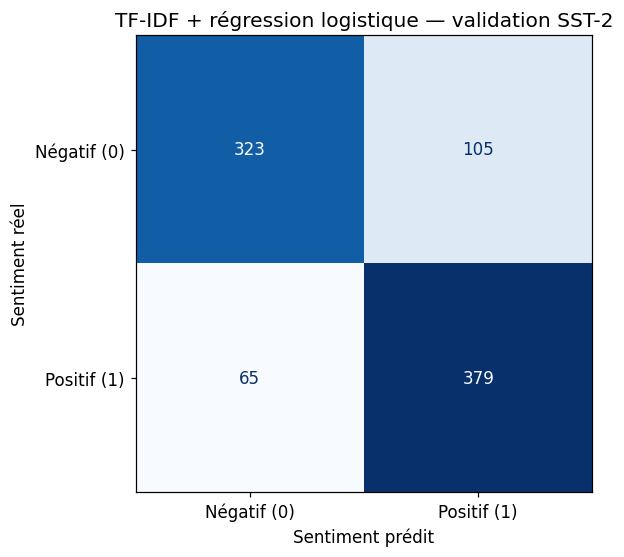

,idx,sentence,true_label,predicted_label,sentiment_reel,sentiment_predit
0,728,"but taken as a stylish and energetic one-shot , the queen of the damned can not be said to suck .",1,0,positif,négatif
1,133,"the tale of tok ( andy lau ) , a sleek sociopath on the trail of o ( takashi sorimachi ) , the most legendary of asian hitmen , is too scattershot to take h...",0,1,négatif,positif
2,631,burns never really harnesses to full effect the energetic cast .,0,1,négatif,positif
3,124,"( lawrence bounces ) all over the stage , dancing , running , sweating , mopping his face and generally displaying the wacky talent that brought him fame in...",1,0,positif,négatif
4,749,a working class `` us vs. them '' opera that leaves no heartstring untugged and no liberal cause unplundered .,1,0,positif,négatif
5,847,"... mafia , rap stars and hood rats butt their ugly heads in a regurgitation of cinematic violence that gives brutal birth to an unlikely , but likable , he...",1,0,positif,négatif
6,856,"in a way , the film feels like a breath of fresh air , but only to those that allow it in .",1,0,positif,négatif
7,248,"a full world has been presented onscreen , not some series of carefully structured plot points building to a pat resolution .",1,0,positif,négatif
8,575,"( director ) o'fallon manages to put some lovely pictures up on the big screen , but his skill at telling a story -- he also contributed to the screenplay -...",0,1,négatif,positif
9,296,its well of thorn and vinegar ( and simple humanity ) has long been plundered by similar works featuring the insight and punch this picture so conspicuously...,0,1,négatif,positif


La baseline atteint **80.50% d'accuracy** et un **F1 positif de 0.8168**, avec **170 erreurs**. La matrice compte **105 faux positifs** et **65 faux négatifs**. Les exemples affichés permettent d'examiner des hypothèses comme la négation, les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant chaque phrase. Ces résultats constituent le point de départ de la future comparaison.

In [7]:
def compute_binary_metrics(y_true, predictions):
    """Évaluer des labels binaires alignés ; la classe positive est toujours 1."""
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    if y_true.ndim != 1 or y_true.shape != predictions.shape or y_true.size == 0:
        raise ValueError("Les labels et prédictions doivent être des vecteurs non vides de même taille.")
    if not np.isin(y_true, [0, 1]).all() or not np.isin(predictions, [0, 1]).all():
        raise ValueError("Seuls les labels binaires 0 et 1 sont acceptés.")
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, pos_label=1, zero_division=0)),
    }


metrics = compute_binary_metrics(y_validation, y_pred)
cm = confusion_matrix(y_validation, y_pred, labels=[0, 1])
n_errors = int(np.count_nonzero(y_validation != y_pred))
assert int(cm.sum()) == len(y_validation)
assert int(cm.sum() - np.trace(cm)) == n_errors
display(pd.DataFrame([metrics], index=["TF-IDF + régression logistique"]).round(4))
print(f"Erreurs : {n_errors} / {len(y_validation)}")

fig_cm, ax_cm = plt.subplots(figsize=(6.4, 5.2))
ConfusionMatrixDisplay(cm, display_labels=["Négatif (0)", "Positif (1)"]).plot(
    ax=ax_cm, cmap="Blues", values_format="d", colorbar=False
)
ax_cm.set(title="TF-IDF + régression logistique — validation SST-2",
          xlabel="Sentiment prédit", ylabel="Sentiment réel")
fig_cm.tight_layout()
plt.show()

predictions_df = pd.DataFrame({
    "idx": validation_df["idx"].to_numpy(),
    "sentence": X_validation,
    "true_label": y_validation,
    "predicted_label": y_pred,
})
errors_df = predictions_df.loc[predictions_df["true_label"] != predictions_df["predicted_label"]].copy()
errors_df["sentiment_reel"] = errors_df["true_label"].map(LABEL_NAMES)
errors_df["sentiment_predit"] = errors_df["predicted_label"].map(LABEL_NAMES)
if len(errors_df):
    display(errors_df.sample(n=min(10, len(errors_df)), random_state=SEED).reset_index(drop=True))
else:
    print("Aucune erreur sur la validation.")

display(Markdown(
    f"La baseline atteint **{metrics['accuracy']:.2%} d'accuracy** et un "
    f"**F1 positif de {metrics['f1']:.4f}**, avec **{n_errors} erreurs**. "
    f"La matrice compte **{int(cm[0, 1])} faux positifs** et **{int(cm[1, 0])} faux négatifs**. "
    "Les exemples affichés permettent d'examiner des hypothèses comme la négation, "
    "les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant "
    "chaque phrase. Ces résultats constituent le point de départ de la future comparaison."
))


### Sauvegarde des résultats réellement calculés

Les fichiers suivants sont créés uniquement après entraînement et évaluation réussis :

- `results/tfidf_metrics.json` : métriques, erreurs, matrice, protocole, hyperparamètres,
  versions et empreintes des données chargées ;
- `results/tfidf_predictions.csv` : les 872 textes de validation dans leur ordre
  officiel, leur identifiant, leur label réel et leur prédiction ;
- `results/tfidf_confusion_matrix.png` : figure lisible avec axes réel/prédit.

Les empreintes des splits facilitent la traçabilité ; elles ne remplacent pas une
révision figée du dépôt de données. Les bornes de dépendances assurent la compatibilité,
pas une reproduction bit à bit entre machines.


In [8]:
metrics_path = RESULTS_DIR / "tfidf_metrics.json"
predictions_path = RESULTS_DIR / "tfidf_predictions.csv"
confusion_path = RESULTS_DIR / "tfidf_confusion_matrix.png"
metrics_payload = {
    **metrics,
    "model": "tfidf_logistic_regression",
    "seed": SEED,
    "positive_label": 1,
    "n_train": len(train_df),
    "n_validation": len(validation_df),
    "n_errors": n_errors,
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_label_order": [0, 1],
    "training_seconds": training_seconds,
    "vocabulary_size": len(baseline.named_steps["tfidf"].vocabulary_),
    "classifier_iterations": baseline.named_steps["logreg"].n_iter_.tolist(),
    "hyperparameters": {"tfidf": TFIDF_PARAMS, "logistic_regression": LOGREG_PARAMS},
    "dataset": {
        "name": "nyu-mll/glue", "configuration": "sst2",
        "fit_split": "train", "evaluation_split": "validation",
        "train_fingerprint": dataset["train"]._fingerprint,
        "validation_fingerprint": dataset["validation"]._fingerprint,
        "normalized_overlap_texts": len(overlap_texts),
        "normalized_overlap_validation_rows": overlap_validation_rows,
    },
    "environment": {"python": platform.python_version(), "platform": platform.system(), "device": "CPU"},
    "library_versions": VERSIONS,
}
metrics_path.write_text(json.dumps(metrics_payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
predictions_df.to_csv(predictions_path, index=False, encoding="utf-8")
fig_cm.savefig(confusion_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig_cm)

# Vérification des exports : schéma, ordre des exemples et cohérence des métriques.
saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
saved_predictions = pd.read_csv(predictions_path, encoding="utf-8", keep_default_na=False)
assert len(saved_predictions) == 872
assert saved_predictions["sentence"].tolist() == X_validation
assert saved_predictions["idx"].tolist() == validation_df["idx"].tolist()
assert saved_predictions["true_label"].tolist() == y_validation.tolist()
assert saved_predictions["predicted_label"].tolist() == y_pred.tolist()
recomputed_metrics = compute_binary_metrics(saved_predictions["true_label"], saved_predictions["predicted_label"])
for name, value in recomputed_metrics.items():
    assert np.isclose(value, saved_metrics[name]), name
assert confusion_path.read_bytes().startswith(b"\x89PNG\r\n\x1a\n")
for path in (metrics_path, predictions_path, confusion_path):
    print(f"Créé et vérifié : {path.name} ({path.stat().st_size:,} octets)")


Créé et vérifié : tfidf_metrics.json (1,717 octets)
Créé et vérifié : tfidf_predictions.csv (101,913 octets)
Créé et vérifié : tfidf_confusion_matrix.png (42,640 octets)


### Récupération dans Colab et arrêt de la phase 1

La cellule suivante crée une archive des **trois résultats réels**. Dans Colab,
elle lance son téléchargement ; si le navigateur le bloque, récupérer les fichiers
dans le panneau **Fichiers → results**. Télécharger également le notebook exécuté
via **Fichier → Télécharger → Télécharger le fichier .ipynb** pour conserver les sorties.

**À faire valider :** notebook exécuté, JSON des métriques, CSV des prédictions et
PNG de la matrice. Aucun score de BERT n'a été calculé. BERT et le reporting
comparatif sont réservés aux phases suivantes.

**Fin de la phase 1.** Attendre la validation explicite :
« Phase 1 validée, passe à la phase 2. »


In [9]:
archive_path = RESULTS_DIR / "phase1_results.zip"
with ZipFile(archive_path, "w") as archive:
    for path in (metrics_path, predictions_path, confusion_path):
        archive.write(path, arcname=path.name)
print(f"Archive des résultats : {archive_path}")
if IN_COLAB:
    from google.colab import files
    files.download(str(archive_path))


Archive des résultats : C:\Users\PAVILION\Downloads\nlp-bert-vs-tfidf-sst2\results\phase1_results.zip


### Références

- Support local : `NLP_Course_Module7_Transformer_BERT (1).pptx`, dans le ZIP fourni,
  consulté en lecture seule ; étapes « Explore » et « Baseline ».
- [Fiche officielle GLUE / SST-2](https://huggingface.co/datasets/nyu-mll/glue).
- [TF-IDF dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- [Régression logistique dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html).
